# 🧠 Sesión 09-A: Transfer Learning — Feature Extraction

**Alumna:** Paucar Ramírez Ariana Carolina
**Curso:** IS056B — Ingeniería del Conocimiento
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Universidad:** UNCP — Facultad de Ingeniería de Sistemas
**Semestre:** 2026-II | **Unidad II:** Transferencia de Aprendizaje, Series de Tiempo y MLOps

---

### 🎯 Objetivos de este notebook
1. **Comprender** qué es Transfer Learning y por qué supera al entrenamiento desde cero
2. **Implementar** Feature Extraction con backbones pre-entrenados de Keras
3. **Practicar** con 2 ejemplos progresivos usando datasets públicos
4. **Visualizar** features transferidos y comparar rendimiento de diferentes backbones

### 📚 Estructura
| Ejemplo | Nivel | Dataset | Modelo Base | Enfoque |
|---------|-------|---------|-------------|---------|
| 1 | 🟢 Básico | Abejas vs Avispas | MobileNetV2 | Primer Feature Extraction |
| 2 | 🟡 Intermedio | Intel Image Classification (6 clases) | EfficientNetB0 | EDA + Augmentation + Métricas |

## ⚙️ Configuración del Entorno

Verificamos GPU disponible e instalamos dependencias.

In [2]:
# Verificar GPU
import subprocess
gpu_info = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                          '--format=csv,noheader'], capture_output=True, text=True)
print("🖥️ GPU detectada:", gpu_info.stdout.strip() or "⚠️ No hay GPU — activa en Runtime > Change runtime type > T4 GPU")

🖥️ GPU detectada: Tesla T4, 15360 MiB


In [3]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Configuración global
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print(f"✅ TensorFlow {tf.__version__}")
print(f"✅ GPU disponible: {tf.config.list_physical_devices('GPU')}")

✅ TensorFlow 2.21.0
✅ GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# 🟢 Ejemplo 1 — Básico: Abejas vs Avispas con MobileNetV2

**Objetivo:** Primer contacto con Feature Extraction. Clasificación binaria (abejas vs avispas) usando MobileNetV2 pre-entrenado en ImageNet.

**Dataset:** [Bee or wasp?](https://www.kaggle.com/datasets/jerzydziewierz/bee-vs-wasp) — 8,126 imágenes seleccionadas para clasificación binaria: 3,183 de abejas y 4,943 de avispas.

**¿Por qué MobileNetV2?** Es ligero (~3.4M parámetros), rápido y perfecto para empezar.

### 1.1. Cargar y explorar el dataset

In [7]:
%pip install -q kagglehub

from pathlib import Path
import kagglehub
import pandas as pd
import tensorflow as tf

# Descargar las fotos y las etiquetas desde Kaggle
carpeta = Path(kagglehub.dataset_download("jerzydziewierz/bee-vs-wasp"))
ruta_csv = next(carpeta.rglob("labels.csv"), None)

if ruta_csv is None:
    raise FileNotFoundError("No se encontró labels.csv en el dataset descargado.")

df = pd.read_csv(ruta_csv)

# Conservar únicamente abejas y avispas
etiquetas = {"bee": 0, "wasp": 1}
df = df[df["label"].isin(etiquetas)].copy()
df["clase"] = df["label"].map(etiquetas)

# Relacionar las rutas del CSV con las fotos descargadas
rutas = {}
for foto in carpeta.rglob("*"):
    if foto.is_file() and foto.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        rutas[f"{foto.parent.name}/{foto.name}"] = str(foto)

df["ruta"] = df["path"].str.replace("\\", "/", regex=False).map(rutas)

faltantes = df["ruta"].isna()
if faltantes.any():
    ejemplos = df.loc[faltantes, "path"].head(3).tolist()
    raise FileNotFoundError(f"Faltan {faltantes.sum()} fotos. Ejemplos: {ejemplos}")

# Separar entrenamiento, validación y prueba según el CSV
es_prueba = df["is_final_validation"].eq(1)
es_validacion = df["is_validation"].eq(1)

train_df = df[~es_prueba & ~es_validacion]
val_df = df[~es_prueba & es_validacion]
test_df = df[es_prueba]

def leer_imagen(ruta, etiqueta):
    imagen = tf.io.decode_image(
        tf.io.read_file(ruta), channels=3, expand_animations=False
    )
    imagen.set_shape([None, None, 3])
    return imagen, etiqueta

def crear_dataset(datos):
    dataset = tf.data.Dataset.from_tensor_slices(
        (datos["ruta"].tolist(), datos["clase"].to_numpy(dtype="int32"))
    )
    return dataset.map(leer_imagen, num_parallel_calls=tf.data.AUTOTUNE)

train_raw = crear_dataset(train_df)
val_raw = crear_dataset(val_df)
test_raw = crear_dataset(test_df)

NUM_CLASSES_1 = 2
CLASS_NAMES_1 = ["abeja", "avispa"]

print(f"Clases: {CLASS_NAMES_1}")
print(f"Train: {len(train_df):,} imágenes")
print(f"Val:   {len(val_df):,} imágenes")
print(f"Test:  {len(test_df):,} imágenes")

Using Colab cache for faster access to the 'bee-vs-wasp' dataset.
Clases: ['abeja', 'avispa']
Train: 5,635 imágenes
Val:   1,234 imágenes
Test:  1,257 imágenes


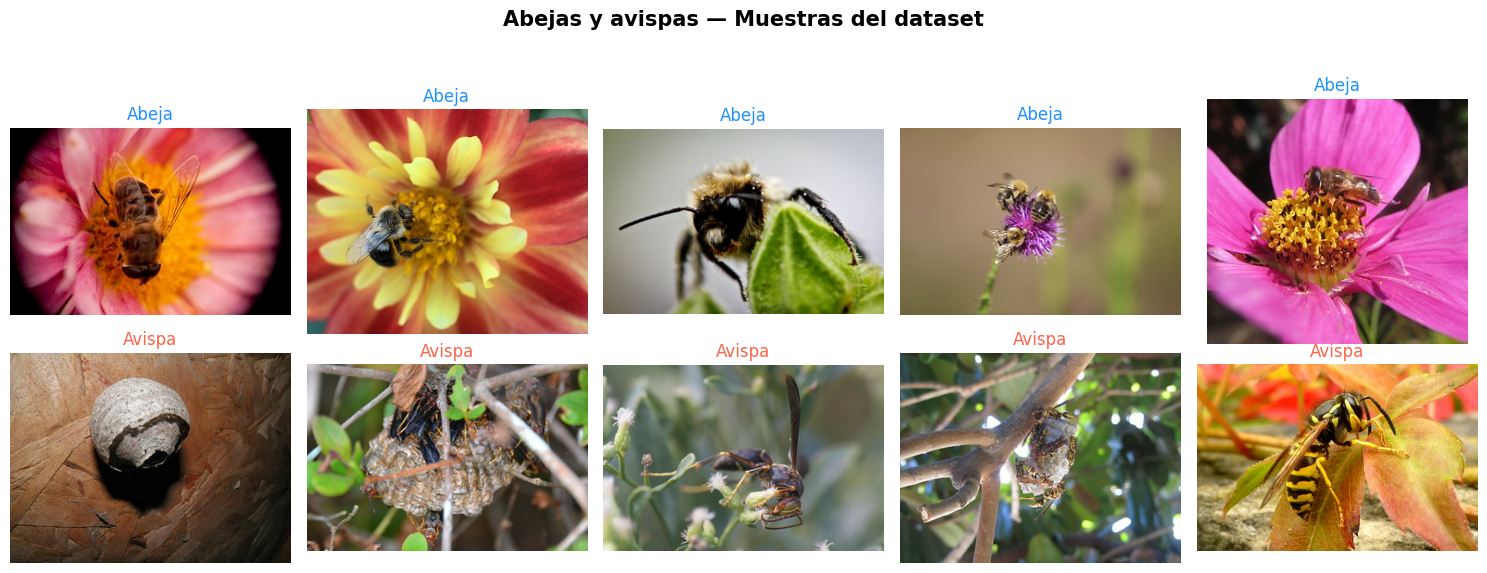

In [8]:
# Visualizar muestras
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
colores = ["dodgerblue", "tomato"]

for clase, nombre in enumerate(CLASS_NAMES_1):
    # Seleccionar cinco imágenes de esta clase
    muestras = train_raw.filter(
        lambda imagen, etiqueta: etiqueta == clase
    ).take(5)

    for ax in axes[clase]:
        ax.axis("off")

    for ax, (imagen, _) in zip(axes[clase], muestras):
        ax.imshow(imagen.numpy())
        ax.set_title(nombre.capitalize(), fontsize=12, color=colores[clase])

fig.suptitle("Abejas y avispas — Muestras del dataset",
             fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### 1.2. Preprocesamiento

MobileNetV2 espera imágenes de **224×224** píxeles. Cada modelo tiene su propio `preprocess_input` que normaliza los píxeles al rango que usó durante su entrenamiento en ImageNet.

In [9]:
import tensorflow as tf

IMG_SIZE_1 = (224, 224)
BATCH_SIZE = 32
SEED = 42

def preprocess_example1(imagen, etiqueta):
    # Redimensionar y ajustar los píxeles al rango [-1, 1]
    imagen = tf.image.resize(imagen, IMG_SIZE_1)
    imagen = tf.keras.applications.mobilenet_v2.preprocess_input(imagen)

    # Abeja (0) → [1, 0]; avispa (1) → [0, 1]
    etiqueta = tf.one_hot(etiqueta, depth=NUM_CLASSES_1)
    return imagen, etiqueta

def preparar_dataset(dataset, entrenamiento=False):
    dataset = dataset.map(
        preprocess_example1,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Mezclar únicamente las imágenes de entrenamiento
    if entrenamiento:
        dataset = dataset.shuffle(1000, seed=SEED)

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds_1 = preparar_dataset(train_raw, entrenamiento=True)
val_ds_1 = preparar_dataset(val_raw)
test_ds_1 = preparar_dataset(test_raw)

# Verificar un lote de entrenamiento
for imagenes, etiquetas in train_ds_1.take(1):
    print(f"✅ Forma de las imágenes: {imagenes.shape}")
    print(f"✅ Forma de las etiquetas: {etiquetas.shape}")
    print(f"✅ Rango de píxeles: [{tf.reduce_min(imagenes).numpy():.2f}, "
          f"{tf.reduce_max(imagenes).numpy():.2f}]")

✅ Forma de las imágenes: (32, 224, 224, 3)
✅ Forma de las etiquetas: (32, 2)
✅ Rango de píxeles: [-1.00, 1.00]


### 1.3. Construir modelo con Feature Extraction

**Pasos clave:**
1. Cargar MobileNetV2 **sin** el clasificador (`include_top=False`)
2. **Congelar** todas sus capas (`trainable = False`)
3. Agregar nuestro clasificador binario

In [10]:
from tensorflow.keras import layers, models

# 1. Cargar MobileNetV2 con los pesos preentrenados de ImageNet
base_model_1 = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE_1, 3)
)

# 2. Congelar las capas de MobileNetV2
base_model_1.trainable = False

# 3. Agregar el clasificador de abejas y avispas
entradas = layers.Input(shape=(*IMG_SIZE_1, 3))
x = base_model_1(entradas, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
salidas = layers.Dense(NUM_CLASSES_1, activation="softmax")(x)

model_1 = models.Model(entradas, salidas, name="abejas_avispas_mobilenetv2")

print("Modelo base: MobileNetV2")
print(f"Capas del modelo base: {len(base_model_1.layers)}")
print(f"Parámetros del modelo base: {base_model_1.count_params():,}")
print(f"Modelo base entrenable: {base_model_1.trainable}")
print(f"Forma de salida del modelo base: {base_model_1.output_shape}")
print(f"Clases de salida: {CLASS_NAMES_1}")

model_1.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Modelo base: MobileNetV2
Capas del modelo base: 154
Parámetros del modelo base: 2,257,984
Modelo base entrenable: False
Forma de salida del modelo base: (None, 7, 7, 1280)
Clases de salida: ['abeja', 'avispa']


Model: "abejas_avispas_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
from tensorflow.keras import layers, models

# MobileNetV2 congelado + clasificador de abejas y avispas
model_1 = models.Sequential([
    layers.Input(shape=(*IMG_SIZE_1, 3)),
    base_model_1,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES_1, activation="softmax")
], name="abejas_avispas_mobilenetv2_FE")

model_1.summary()

# Contar parámetros
total = model_1.count_params()
entrenables = sum(tf.size(p).numpy() for p in model_1.trainable_weights)
congelados = total - entrenables

print(f"\nClases de salida: {CLASS_NAMES_1}")
print(f"Parámetros totales: {total:,}")
print(f"Entrenables: {entrenables:,} ({entrenables / total:.2%})")
print(f"Congelados: {congelados:,} ({congelados / total:.2%})")

Model: "abejas_avispas_mobilenetv2_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Clases de salida: ['abeja', 'avispa']
Parámetros totales: 2,260,546
Entrenables: 2,562 (0.11%)
Congelados: 2,257,984 (99.89%)


### 1.4. Entrenar y evaluar

In [12]:
# Compilar el modelo de abejas y avispas
model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Entrenar hasta 8 épocas
history_1 = model_1.fit(
    train_ds_1,
    validation_data=val_ds_1,
    epochs=8,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)

# Mostrar la mejor exactitud de validación registrada
mejor_exactitud = max(history_1.history["val_accuracy"])
print(f"\n🏆 Mejor exactitud en validación: {mejor_exactitud:.2%}")

Epoch 1/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 63s 231ms/step - accuracy: 0.9098 - loss: 0.3107 - val_accuracy: 0.7601 - val_loss: 0.5899
Epoch 2/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 16s 78ms/step - accuracy: 0.9363 - loss: 0.2159 - val_accuracy: 0.8282 - val_loss: 0.4796
Epoch 3/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 16s 80ms/step - accuracy: 0.9528 - loss: 0.1649 - val_accuracy: 0.8687 - val_loss: 0.4006
Epoch 4/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 15s 77ms/step - accuracy: 0.9560 - loss: 0.1431 - val_accuracy: 0.8947 - val_loss: 0.3552
Epoch 5/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 22s 114ms/step - accuracy: 0.9608 - loss: 0.1301 - val_accuracy: 0.9068 - val_loss: 0.3249
Epoch 6/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 20s 95ms/step - accuracy: 0.9652 - loss: 0.1186 - val_accuracy: 0.9165 - val_loss: 0.2874
Epoch 7/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 18s 95ms/step - accuracy: 0.9645 - loss: 0.1225 - val_accuracy: 0.9028 - val_loss: 0.3479
Epoch 8/8
177/177 ━━━━━━━━━━━━━━━━━━━━ 17s 76ms/step - accuracy: 0.9656 - loss: 0.1227 - val_ac

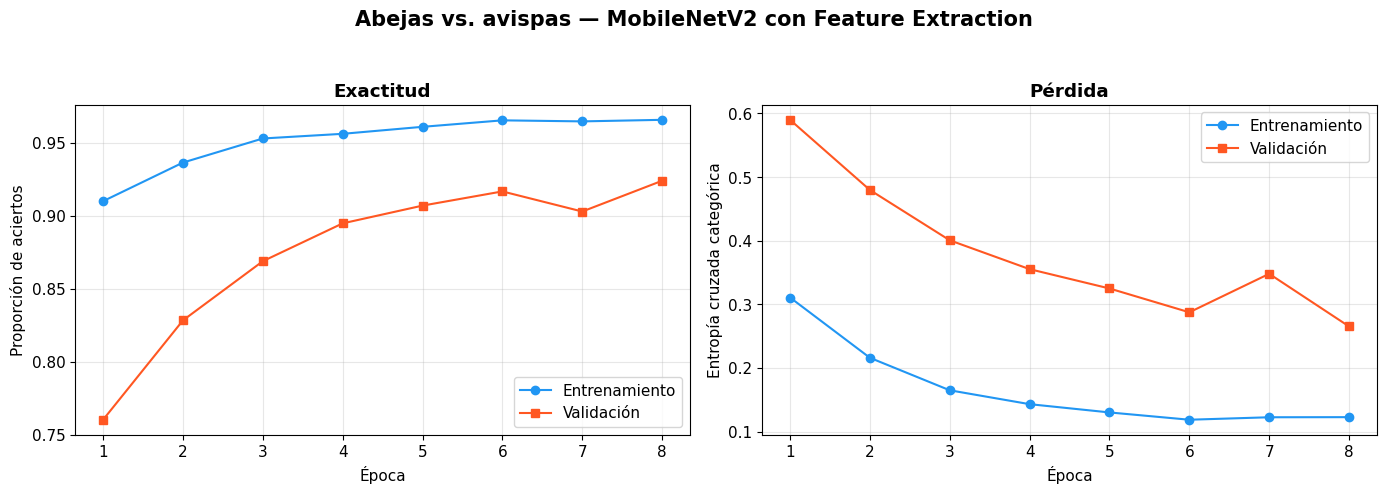

In [13]:
import matplotlib.pyplot as plt

# Resultados de las épocas que se ejecutaron
resultados = history_1.history
epocas = range(1, len(resultados["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Exactitud
axes[0].plot(epocas, resultados["accuracy"], "o-",
             label="Entrenamiento", color="#2196F3")
axes[0].plot(epocas, resultados["val_accuracy"], "s-",
             label="Validación", color="#FF5722")
axes[0].set_title("Exactitud", fontweight="bold")
axes[0].set_ylabel("Proporción de aciertos")

# Pérdida
axes[1].plot(epocas, resultados["loss"], "o-",
             label="Entrenamiento", color="#2196F3")
axes[1].plot(epocas, resultados["val_loss"], "s-",
             label="Validación", color="#FF5722")
axes[1].set_title("Pérdida", fontweight="bold")
axes[1].set_ylabel("Entropía cruzada categórica")

for ax in axes:
    ax.set_xlabel("Época")
    ax.set_xticks(list(epocas))
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle("Abejas vs. avispas — MobileNetV2 con Feature Extraction",
             fontsize=15, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### 1.5. Predicciones visuales

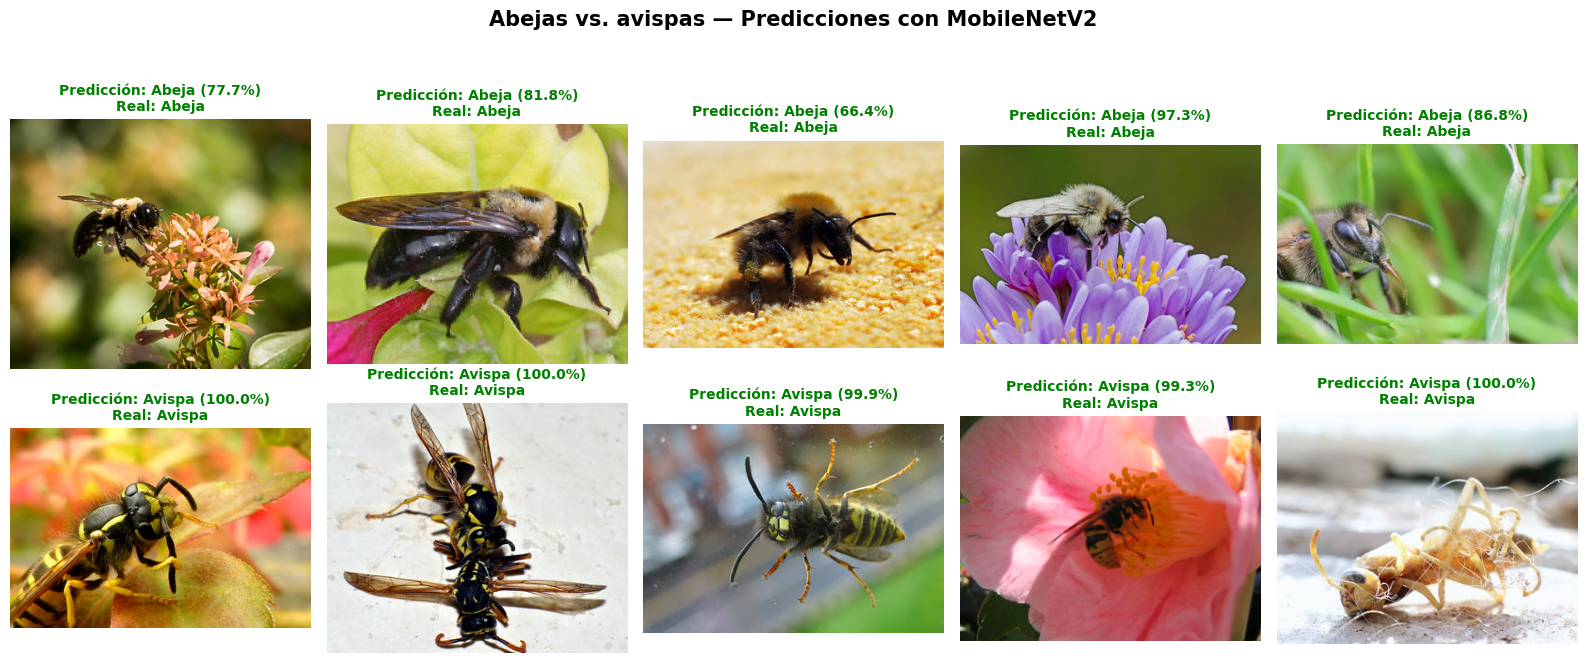


### ✅ Conclusión — Clasificación de abejas y avispas

| Métrica | Valor |
|---|---|
| Modelo base | MobileNetV2 preentrenado en ImageNet |
| Clases | Abeja y avispa |
| Parámetros congelados | 2,257,984 |
| Parámetros entrenados | 2,562 (solo el clasificador) |
| Épocas ejecutadas | 8 |
| Mejor exactitud de validación | 92.38% |

> Con **Feature Extraction**, MobileNetV2 extrajo características de las fotos
> de abejas y avispas. Al entrenar solo el clasificador, se ajustaron
> **0.11% de los parámetros** del modelo. La mayor
> proporción de aciertos observada en validación fue de **92.38%**.


In [15]:
import matplotlib.pyplot as plt
import tensorflow as tf

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for clase in range(NUM_CLASSES_1):
    # Una fila por clase real: abejas arriba y avispas abajo
    muestras = val_raw.filter(
        lambda imagen, etiqueta: etiqueta == clase
    ).take(5)

    for ax in axes[clase]:
        ax.axis("off")

    for ax, (imagen, etiqueta) in zip(axes[clase], muestras):
        # Usar el mismo preprocesamiento del entrenamiento
        imagen_prep, _ = preprocess_example1(imagen, etiqueta)
        lote = tf.expand_dims(imagen_prep, axis=0)

        probabilidades = model_1(lote, training=False)[0].numpy()
        clase_predicha = int(probabilidades.argmax())
        clase_real = int(etiqueta.numpy())
        probabilidad = probabilidades[clase_predicha]

        nombre_predicho = CLASS_NAMES_1[clase_predicha].capitalize()
        nombre_real = CLASS_NAMES_1[clase_real].capitalize()
        color = "green" if clase_predicha == clase_real else "red"

        ax.imshow(imagen.numpy())
        ax.set_title(
            f"Predicción: {nombre_predicho} ({probabilidad:.1%})\n"
            f"Real: {nombre_real}",
            fontsize=10,
            color=color,
            fontweight="bold"
        )

fig.suptitle(
    "Abejas vs. avispas — Predicciones con MobileNetV2",
    fontsize=15,
    fontweight="bold"
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()
from IPython.display import Markdown, display

resultados = history_1.history
epocas = len(resultados["val_accuracy"])
mejor_exactitud = max(resultados["val_accuracy"])

total = model_1.count_params()
entrenables = sum(
    int(tf.size(peso).numpy()) for peso in model_1.trainable_weights
)
congelados = total - entrenables

display(Markdown(f"""
### ✅ Conclusión — Clasificación de abejas y avispas

| Métrica | Valor |
|---|---|
| Modelo base | MobileNetV2 preentrenado en ImageNet |
| Clases | Abeja y avispa |
| Parámetros congelados | {congelados:,} |
| Parámetros entrenados | {entrenables:,} (solo el clasificador) |
| Épocas ejecutadas | {epocas} |
| Mejor exactitud de validación | {mejor_exactitud:.2%} |

> Con **Feature Extraction**, MobileNetV2 extrajo características de las fotos
> de abejas y avispas. Al entrenar solo el clasificador, se ajustaron
> **{entrenables / total:.2%} de los parámetros** del modelo. La mayor
> proporción de aciertos observada en validación fue de **{mejor_exactitud:.2%}**.
"""))

---
# 🟡 Ejemplo 2 — Intermedio: Escenas naturales y urbanas con EfficientNetB0

**Objetivo.** Clasificar fotografías en seis categorías mediante extracción de características (*Feature Extraction*).

**Dataset.** [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification) — 17,034 imágenes etiquetadas de seis clases: edificios, bosques, glaciares, montañas, mar y calles. Se destinan 11,227 imágenes al entrenamiento, 2,807 a la validación y 3,000 a la prueba.

**¿Por qué EfficientNetB0?** Sus pesos preentrenados en ImageNet permiten reutilizar características visuales como bordes, texturas y formas. Congelaremos el modelo base y entrenaremos un clasificador para nuestras seis clases.

### 2.1. Cargar dataset y EDA

In [1]:
%pip install -q kagglehub

from pathlib import Path

import kagglehub
import tensorflow as tf
from sklearn.model_selection import train_test_split

# Descargar Intel Image Classification desde Kaggle
carpeta_intel = Path(
    kagglehub.dataset_download("puneet6060/intel-image-classification")
)

# Usar las seis clases originales del dataset
clases_intel = {
    "buildings": "Edificios",
    "forest": "Bosques",
    "glacier": "Glaciares",
    "mountain": "Montañas",
    "sea": "Mar",
    "street": "Calles",
}

CLASS_NAMES_2 = list(clases_intel.values())
NUM_CLASSES_2 = len(CLASS_NAMES_2)

# Encontrar las carpetas que contienen las seis clases
def buscar_carpeta_intel(nombre):
    for ruta in carpeta_intel.rglob(nombre):
        if all((ruta / clase).is_dir() for clase in clases_intel):
            return ruta

    raise FileNotFoundError(
        f"No se encontró '{nombre}' con las seis clases en {carpeta_intel}."
    )

# Asociar cada foto con su etiqueta numérica, del 0 al 5
def listar_imagenes_intel(carpeta):
    rutas = []
    etiquetas = []

    for etiqueta, clase in enumerate(clases_intel):
        fotos = sorted(
            foto for foto in (carpeta / clase).iterdir()
            if foto.is_file() and foto.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )

        if not fotos:
            raise FileNotFoundError(f"No se encontraron imágenes en {carpeta / clase}.")

        rutas.extend(str(foto) for foto in fotos)
        etiquetas.extend([etiqueta] * len(fotos))

    return rutas, etiquetas

rutas, etiquetas = listar_imagenes_intel(buscar_carpeta_intel("seg_train"))
rutas_test, etiquetas_test = listar_imagenes_intel(buscar_carpeta_intel("seg_test"))

# Dividir seg_train en 80 % de entrenamiento y 20 % de validación
# La estratificación conserva aproximadamente la proporción de cada clase
rutas_train, rutas_val, etiquetas_train, etiquetas_val = train_test_split(
    rutas,
    etiquetas,
    test_size=0.20,
    random_state=42,
    stratify=etiquetas
)

# Leer las fotos en RGB y devolver pares (imagen, etiqueta)
def leer_imagen_intel(ruta, etiqueta):
    imagen = tf.io.decode_image(
        tf.io.read_file(ruta),
        channels=3,
        expand_animations=False
    )
    imagen.set_shape([None, None, 3])
    return imagen, etiqueta

def crear_dataset_intel(rutas_imagenes, etiquetas_imagenes):
    dataset = tf.data.Dataset.from_tensor_slices(
        (rutas_imagenes, etiquetas_imagenes)
    )
    return dataset.map(leer_imagen_intel, num_parallel_calls=tf.data.AUTOTUNE)

train_raw_2 = crear_dataset_intel(rutas_train, etiquetas_train)
val_raw_2 = crear_dataset_intel(rutas_val, etiquetas_val)
test_raw_2 = crear_dataset_intel(rutas_test, etiquetas_test)

print(f"📊 Clases ({NUM_CLASSES_2}): {CLASS_NAMES_2}")
print(f"📊 Entrenamiento: {len(rutas_train):,} imágenes")
print(f"📊 Validación:    {len(rutas_val):,} imágenes")
print(f"📊 Prueba:        {len(rutas_test):,} imágenes")
print(f"📊 Total:         {len(rutas) + len(rutas_test):,} imágenes etiquetadas")

Using Colab cache for faster access to the 'intel-image-classification' dataset.
📊 Clases (6): ['Edificios', 'Bosques', 'Glaciares', 'Montañas', 'Mar', 'Calles']
📊 Entrenamiento: 11,227 imágenes
📊 Validación:    2,807 imágenes
📊 Prueba:        3,000 imágenes
📊 Total:         17,034 imágenes etiquetadas


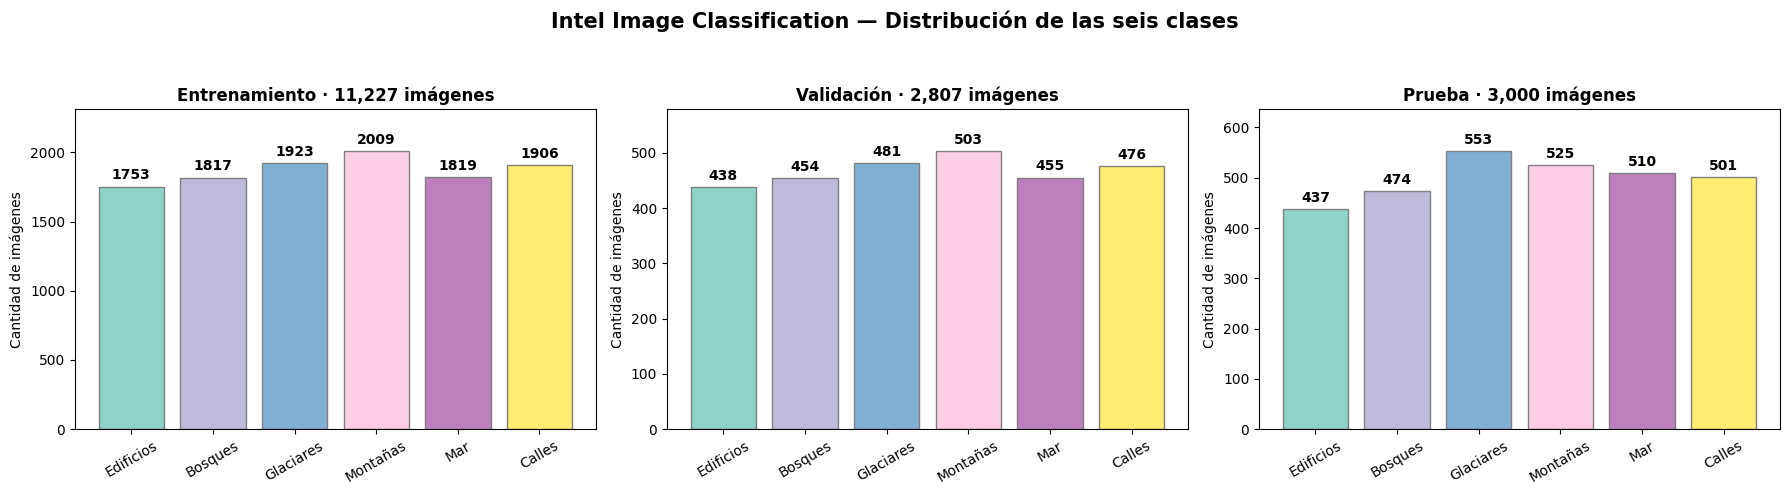

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Contar las etiquetas guardadas en la celda de carga
# Así podemos graficar sin volver a abrir todas las imágenes
conjuntos = [
    ("Entrenamiento", etiquetas_train),
    ("Validación", etiquetas_val),
    ("Prueba", etiquetas_test),
]

colores = plt.cm.Set3(np.linspace(0, 1, NUM_CLASSES_2))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nombre, etiquetas_split) in zip(axes, conjuntos):
    cantidades = np.bincount(etiquetas_split, minlength=NUM_CLASSES_2)

    barras = ax.bar(
        CLASS_NAMES_2, cantidades, color=colores, edgecolor="gray"
    )

    ax.bar_label(barras, padding=3, fontsize=10, fontweight="bold")
    ax.set_title(f"{nombre} · {len(etiquetas_split):,} imágenes",
                 fontweight="bold")
    ax.set_ylabel("Cantidad de imágenes")
    ax.tick_params(axis="x", labelrotation=30)
    ax.margins(y=0.15)

fig.suptitle("Intel Image Classification — Distribución de las seis clases",
             fontsize=15, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

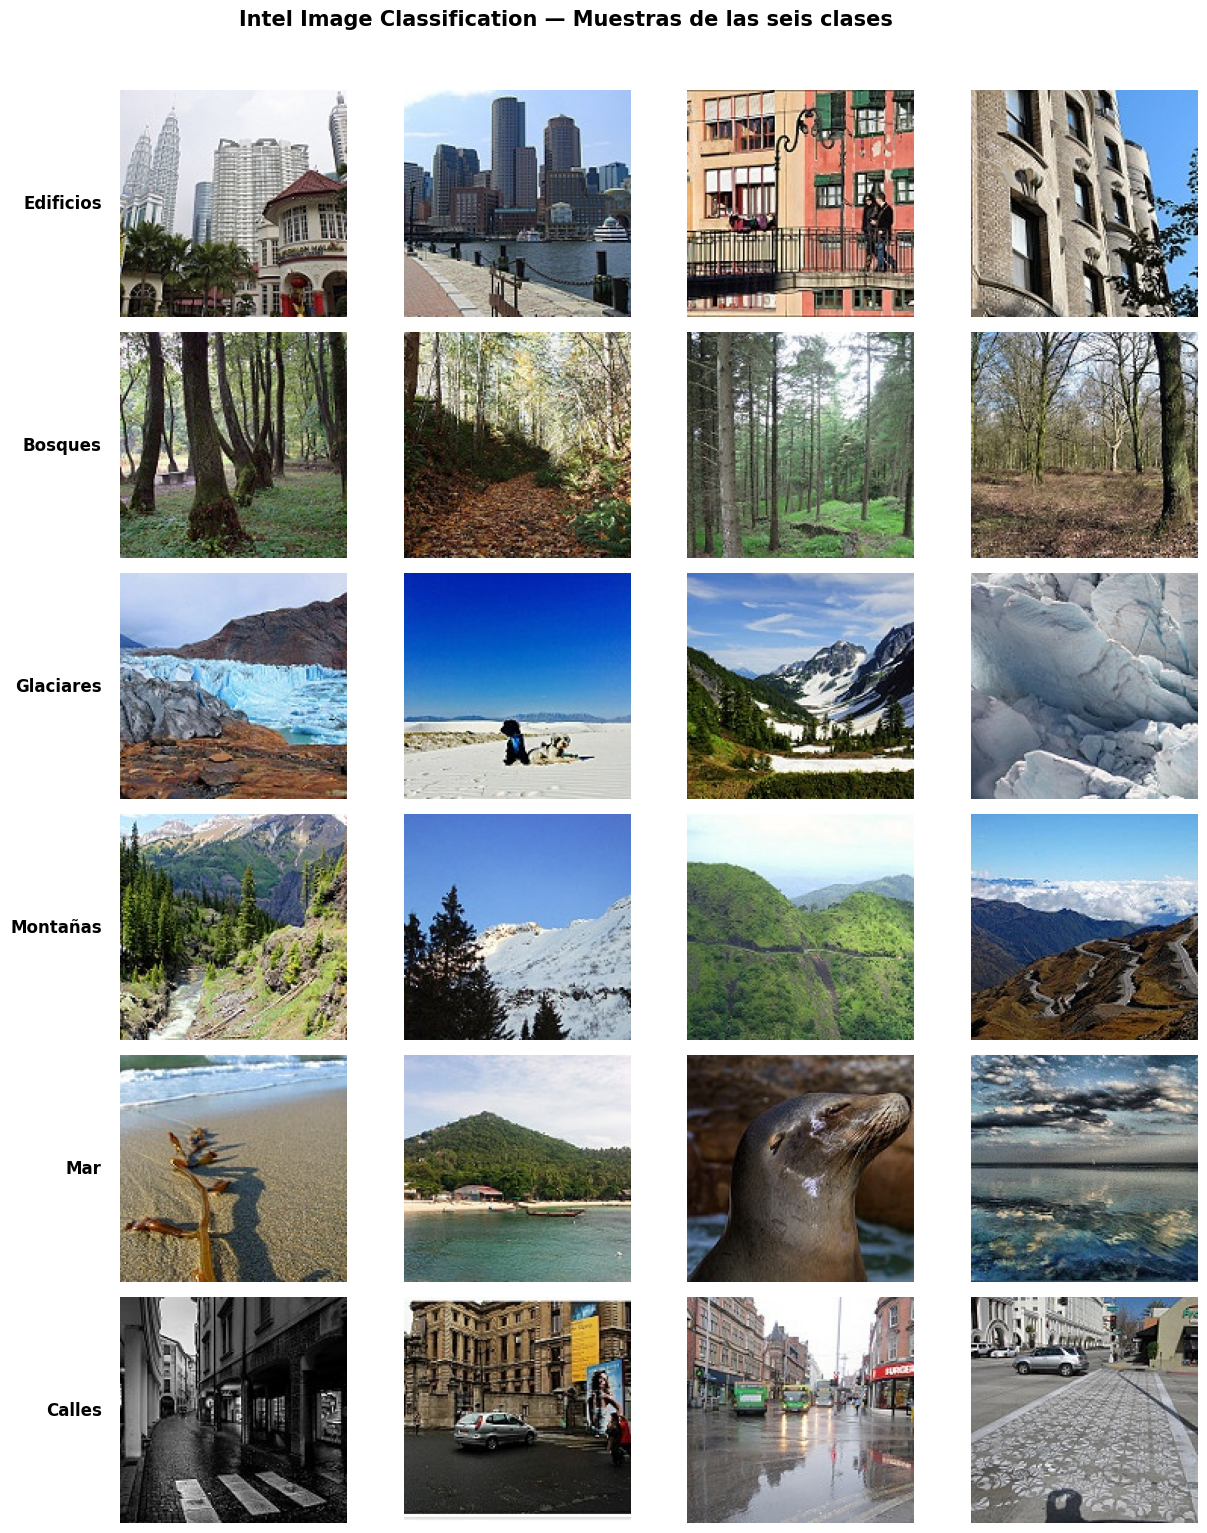

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Mostrar cuatro fotos de entrenamiento por cada una de las seis clases
fotos_por_clase = 4
rng = np.random.default_rng(42)
etiquetas_array = np.asarray(etiquetas_train)

fig, axes = plt.subplots(
    NUM_CLASSES_2, fotos_por_clase,
    figsize=(14, 2.6 * NUM_CLASSES_2),
    squeeze=False
)

for clase, nombre in enumerate(CLASS_NAMES_2):
    # Elegir cuatro fotos al azar, sin repetir
    indices_clase = np.flatnonzero(etiquetas_array == clase)
    seleccion = rng.choice(indices_clase, size=fotos_por_clase, replace=False)

    for ax, indice in zip(axes[clase], seleccion):
        imagen = plt.imread(rutas_train[indice])
        ax.imshow(imagen)
        ax.axis("off")

    # Colocar el nombre de la clase a la izquierda de su fila
    axes[clase, 0].text(
        -0.08, 0.5, nombre,
        transform=axes[clase, 0].transAxes,
        ha="right", va="center", fontsize=12, fontweight="bold"
    )

fig.suptitle(
    "Intel Image Classification — Muestras de las seis clases",
    fontsize=15, fontweight="bold"
)
fig.tight_layout(rect=[0.08, 0, 1, 0.96])
plt.show()

### 2.2. Preprocesamiento con Data Augmentation

Para mejorar la generalización, aplicamos **Data Augmentation solo al conjunto de entrenamiento**. EfficientNet tiene su propio `preprocess_input` que escala los píxeles de forma particular.

In [4]:
import tensorflow as tf
from tensorflow.keras import layers

IMG_SIZE_2 = (224, 224)
BATCH_SIZE_2 = 32
SEED_2 = 42

# Aumento de datos para las fotos de entrenamiento
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED_2),
    layers.RandomRotation(0.05, seed=SEED_2 + 1),
    layers.RandomZoom(0.15, seed=SEED_2 + 2),
    layers.RandomContrast(0.10, seed=SEED_2 + 3),
], name="aumento_escenas_intel")

def preprocess_val_2(imagen, etiqueta):
    # EfficientNetB0 recibe píxeles en [0, 255] y los reescala internamente
    imagen = tf.image.resize(imagen, IMG_SIZE_2)

    # Convertir cada etiqueta en un vector con seis posiciones
    etiqueta = tf.one_hot(etiqueta, depth=NUM_CLASSES_2)
    return imagen, etiqueta

def preprocess_train_2(imagen, etiqueta):
    imagen, etiqueta = preprocess_val_2(imagen, etiqueta)
    imagen = data_augmentation(imagen, training=True)
    imagen = tf.clip_by_value(imagen, 0.0, 255.0)
    return imagen, etiqueta

train_ds_2 = (
    train_raw_2
    .shuffle(1000, seed=SEED_2)
    .map(preprocess_train_2, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE_2)
    .prefetch(tf.data.AUTOTUNE)
)

# Validación y prueba usan el mismo preprocesamiento sin aumentos
def preparar_evaluacion_2(dataset):
    return (
        dataset
        .map(preprocess_val_2, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(BATCH_SIZE_2)
        .prefetch(tf.data.AUTOTUNE)
    )

val_ds_2 = preparar_evaluacion_2(val_raw_2)
test_ds_2 = preparar_evaluacion_2(test_raw_2)

# Verificar el primer lote
for imagenes, etiquetas in train_ds_2.take(1):
    print(f"✅ Forma de las imágenes: {imagenes.shape}")
    print(f"✅ Forma de las etiquetas: {etiquetas.shape}")

✅ Forma de las imágenes: (32, 224, 224, 3)
✅ Forma de las etiquetas: (32, 6)


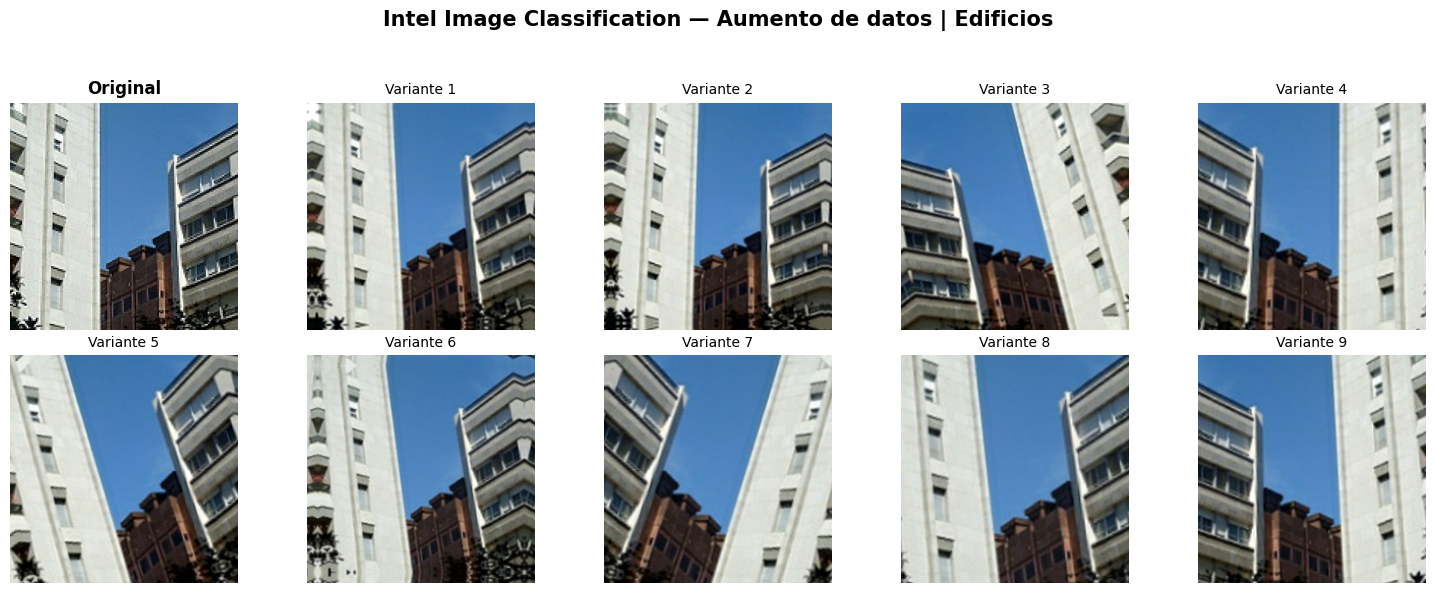

In [5]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Tomar una imagen del conjunto de entrenamiento
imagen_original, etiqueta = next(iter(train_raw_2))
nombre_clase = CLASS_NAMES_2[int(etiqueta.numpy())]

# Preparar la imagen para aplicar el aumento de datos
imagen_redimensionada = tf.image.resize(imagen_original, IMG_SIZE_2)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

# Mostrar la foto original en el primer espacio
axes[0, 0].imshow(imagen_original.numpy())
axes[0, 0].set_title("Original", fontweight="bold")
axes[0, 0].axis("off")

# Generar nueve variantes de la misma foto
for numero, ax in enumerate(axes.flat[1:], start=1):
    # Pasamos la imagen directamente sin dimensión de lote
    imagen_aumentada = data_augmentation(imagen_redimensionada, training=True)

    # Mantener los píxeles en el rango válido para visualizar la imagen
    imagen_visible = tf.cast(
        tf.clip_by_value(imagen_aumentada, 0, 255),
        tf.uint8
    )

    ax.imshow(imagen_visible.numpy())
    ax.set_title(f"Variante {numero}", fontsize=10)
    ax.axis("off")

fig.suptitle(
    f"Intel Image Classification — Aumento de datos | {nombre_clase}",
    fontsize=15,
    fontweight="bold"
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### 2.3. Construir modelo con EfficientNetB0

In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Cargar EfficientNetB0 con los pesos preentrenados de ImageNet
base_model_2 = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE_2, 3)
)

# Congelar el modelo base para la extracción de características
base_model_2.trainable = False

# Construir el clasificador de las seis clases de Intel
inputs_2 = layers.Input(shape=(*IMG_SIZE_2, 3))
x = base_model_2(inputs_2, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.2)(x)
outputs_2 = layers.Dense(NUM_CLASSES_2, activation="softmax")(x)

model_2 = models.Model(
    inputs_2, outputs_2, name="intel_efficientnetb0_FE"
)

# Mostrar la arquitectura y el número de parámetros
model_2.summary()

total = model_2.count_params()
entrenables = sum(
    int(tf.size(peso).numpy()) for peso in model_2.trainable_weights
)

print(f"\nClases de salida ({NUM_CLASSES_2}): {CLASS_NAMES_2}")
print(f"Parámetros totales: {total:,}")
print(f"Parámetros entrenables: {entrenables:,}")
print(f"Parámetros no entrenables: {total - entrenables:,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "intel_efficientnetb0_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,219,433 (16.10 MB)

 Trainable params: 167,302 (653.52 KB)

 Non-trainable params: 4,052,131 (15.46 MB)


Clases de salida (6): ['Edificios', 'Bosques', 'Glaciares', 'Montañas', 'Mar', 'Calles']
Parámetros totales: 4,219,433
Parámetros entrenables: 167,302
Parámetros no entrenables: 4,052,131


### 2.4. Entrenar con callbacks profesionales

In [7]:
# Compilar EfficientNetB0 con el clasificador de las seis clases
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Entrenar el clasificador con EfficientNetB0 congelado
history_2 = model_2.fit(
    train_ds_2,
    validation_data=val_ds_2,
    epochs=15,
    callbacks=[
        # Reducir la tasa de aprendizaje si la pérdida no mejora en 2 épocas
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1
        ),
        # Detener tras 5 épocas sin mejora y recuperar los mejores pesos
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        )
    ]
)

mejor_exactitud = max(history_2.history["val_accuracy"])
print(f"\n🏆 Mayor exactitud registrada en validación: {mejor_exactitud:.2%}")

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 249s 580ms/step - accuracy: 0.8561 - loss: 0.4258 - val_accuracy: 0.9099 - val_loss: 0.2271 - learning_rate: 0.0010
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 147s 418ms/step - accuracy: 0.8902 - loss: 0.2975 - val_accuracy: 0.9216 - val_loss: 0.2091 - learning_rate: 0.0010
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 147s 416ms/step - accuracy: 0.9026 - loss: 0.2630 - val_accuracy: 0.9230 - val_loss: 0.2080 - learning_rate: 0.0010
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 146s 415ms/step - accuracy: 0.9047 - loss: 0.2515 - val_accuracy: 0.9270 - val_loss: 0.2001 - learning_rate: 0.0010
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 204s 422ms/step - accuracy: 0.9136 - loss: 0.2314 - val_accuracy: 0.9202 - val_loss: 0.2082 - learning_rate: 0.0010
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step - accuracy: 0.9177 - loss: 0.2192
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
351/351 ━━━━━━━━━━━━━━━━━━━━ 147s 416ms/step - accuracy:

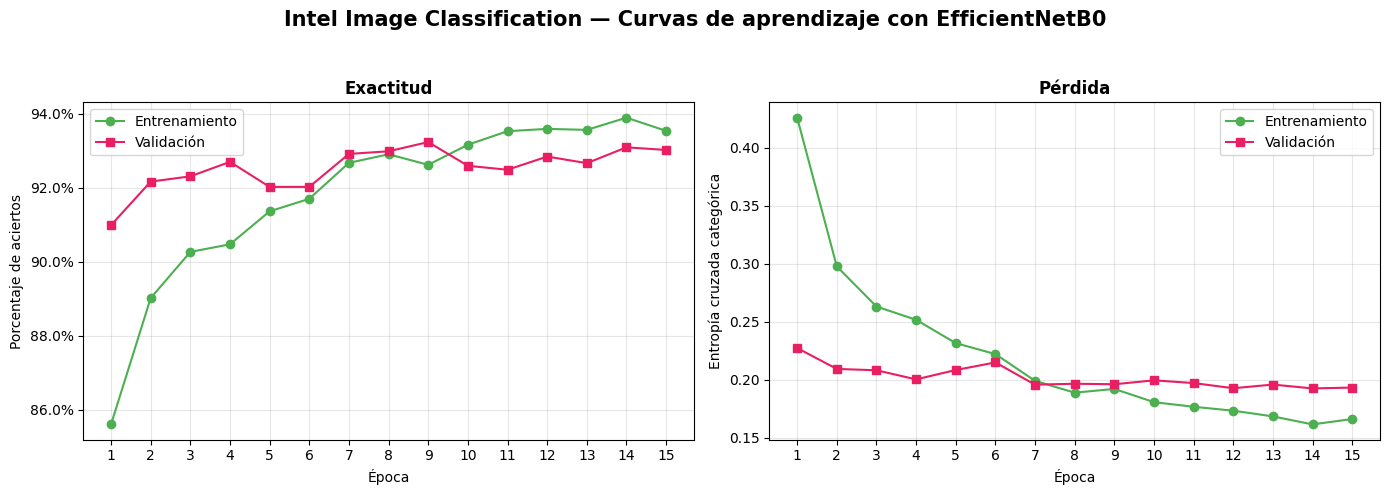

In [8]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Usar solo las épocas que se ejecutaron
resultados = history_2.history
epocas = range(1, len(resultados["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Exactitud de entrenamiento y validación
axes[0].plot(epocas, resultados["accuracy"], "o-",
             label="Entrenamiento", color="#4CAF50")
axes[0].plot(epocas, resultados["val_accuracy"], "s-",
             label="Validación", color="#E91E63")
axes[0].set_title("Exactitud", fontweight="bold")
axes[0].set_ylabel("Porcentaje de aciertos")
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=1))

# Pérdida de entrenamiento y validación
axes[1].plot(epocas, resultados["loss"], "o-",
             label="Entrenamiento", color="#4CAF50")
axes[1].plot(epocas, resultados["val_loss"], "s-",
             label="Validación", color="#E91E63")
axes[1].set_title("Pérdida", fontweight="bold")
axes[1].set_ylabel("Entropía cruzada categórica")

for ax in axes:
    ax.set_xlabel("Época")
    ax.set_xticks(list(epocas))
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    "Intel Image Classification — Curvas de aprendizaje con EfficientNetB0",
    fontsize=15, fontweight="bold"
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### 2.5. Evaluación detallada: Matriz de confusión y reporte de clasificación

📊 Reporte de clasificación — Intel Image Classification
Modelo: EfficientNetB0 | Conjunto: Prueba
              precision    recall  f1-score   support

   Edificios     0.9502    0.9176    0.9336       437
     Bosques     0.9916    0.9958    0.9937       474
   Glaciares     0.8811    0.8843    0.8827       553
    Montañas     0.9073    0.8571    0.8815       525
         Mar     0.9363    0.9804    0.9579       510
      Calles     0.9284    0.9581    0.9430       501

    accuracy                         0.9307      3000
   macro avg     0.9325    0.9322    0.9321      3000
weighted avg     0.9305    0.9307    0.9303      3000



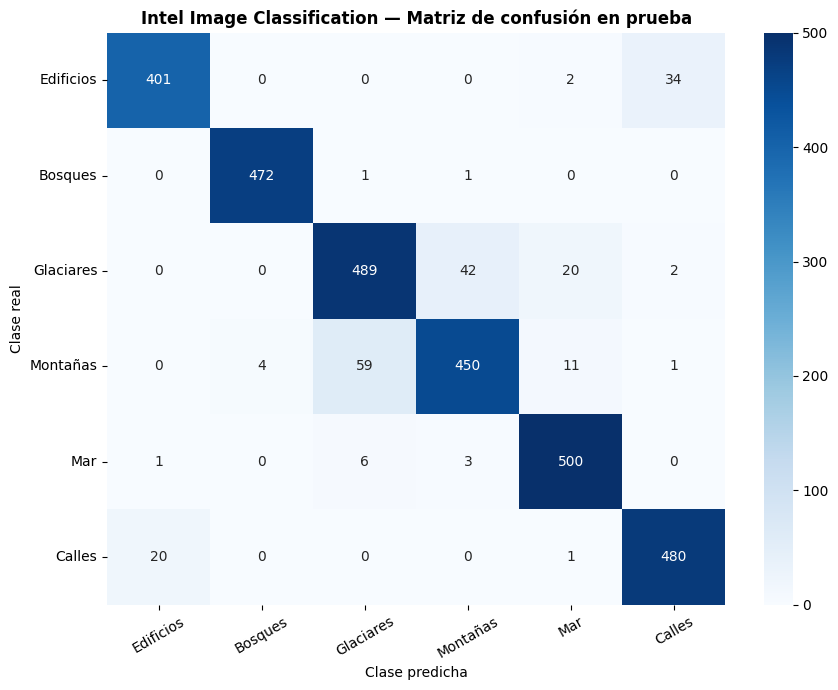

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Obtener las etiquetas reales y las predicciones del conjunto de prueba
y_true, y_pred = [], []

for imagenes, etiquetas in test_ds_2:
    probabilidades = model_2(imagenes, training=False).numpy()

    # Convertir los vectores de seis posiciones en índices de clase
    y_true.extend(np.argmax(etiquetas.numpy(), axis=1))
    y_pred.extend(np.argmax(probabilidades, axis=1))

clases = list(range(NUM_CLASSES_2))

# Mostrar precisión, recall y F1 por cada clase
print("📊 Reporte de clasificación — Intel Image Classification")
print("Modelo: EfficientNetB0 | Conjunto: Prueba")
print(classification_report(
    y_true,
    y_pred,
    labels=clases,
    target_names=CLASS_NAMES_2,
    digits=4,
    zero_division=0
))

# Mostrar los aciertos y errores entre las seis clases
matriz = confusion_matrix(y_true, y_pred, labels=clases)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES_2,
    yticklabels=CLASS_NAMES_2,
    ax=ax
)

ax.set_title("Intel Image Classification — Matriz de confusión en prueba",
             fontweight="bold")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.tick_params(axis="x", labelrotation=30)
ax.tick_params(axis="y", labelrotation=0)
fig.tight_layout()
plt.show()

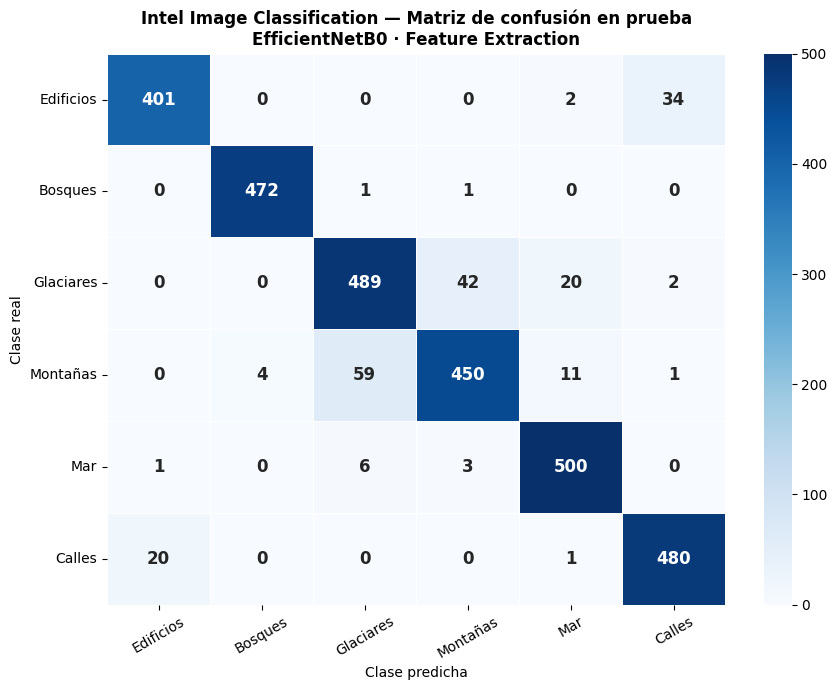


🔍 Principales confusiones (clase real → clase predicha)
  Montañas → Glaciares: 59 errores
  Glaciares → Montañas: 42 errores
  Edificios → Calles: 34 errores
  Glaciares → Mar: 20 errores
  Calles → Edificios: 20 errores
  Montañas → Mar: 11 errores
  Mar → Glaciares: 6 errores
  Montañas → Bosques: 4 errores
  Mar → Montañas: 3 errores


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Matriz de confusión de Intel Image Classification
cm = confusion_matrix(
    y_true, y_pred, labels=list(range(NUM_CLASSES_2))
)

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES_2,
    yticklabels=CLASS_NAMES_2,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 12, "fontweight": "bold"},
    ax=ax
)

ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title(
    "Intel Image Classification — Matriz de confusión en prueba\n"
    "EfficientNetB0 · Feature Extraction",
    fontweight="bold"
)
ax.tick_params(axis="x", labelrotation=30)
ax.tick_params(axis="y", labelrotation=0)

fig.tight_layout()
plt.show()

# Ordenar las confusiones con más de dos errores
confusiones = []

for i in range(NUM_CLASSES_2):
    for j in range(NUM_CLASSES_2):
        if i != j and cm[i, j] > 2:
            confusiones.append((cm[i, j], CLASS_NAMES_2[i], CLASS_NAMES_2[j]))

confusiones.sort(key=lambda fila: fila[0], reverse=True)

print("\n🔍 Principales confusiones (clase real → clase predicha)")
if confusiones:
    for cantidad, real, predicha in confusiones:
        print(f"  {real} → {predicha}: {cantidad} errores")
else:
    print("  Ningún par de clases tuvo más de dos errores.")

### 2.6. Visualización de Feature Maps

Observamos cómo responde EfficientNetB0 a una fotografía de Intel Image Classification. Mostramos la imagen original junto a ocho canales de cuatro capas del modelo base. Cada mapa permite ver en qué zonas de la imagen responde con mayor intensidad ese canal.

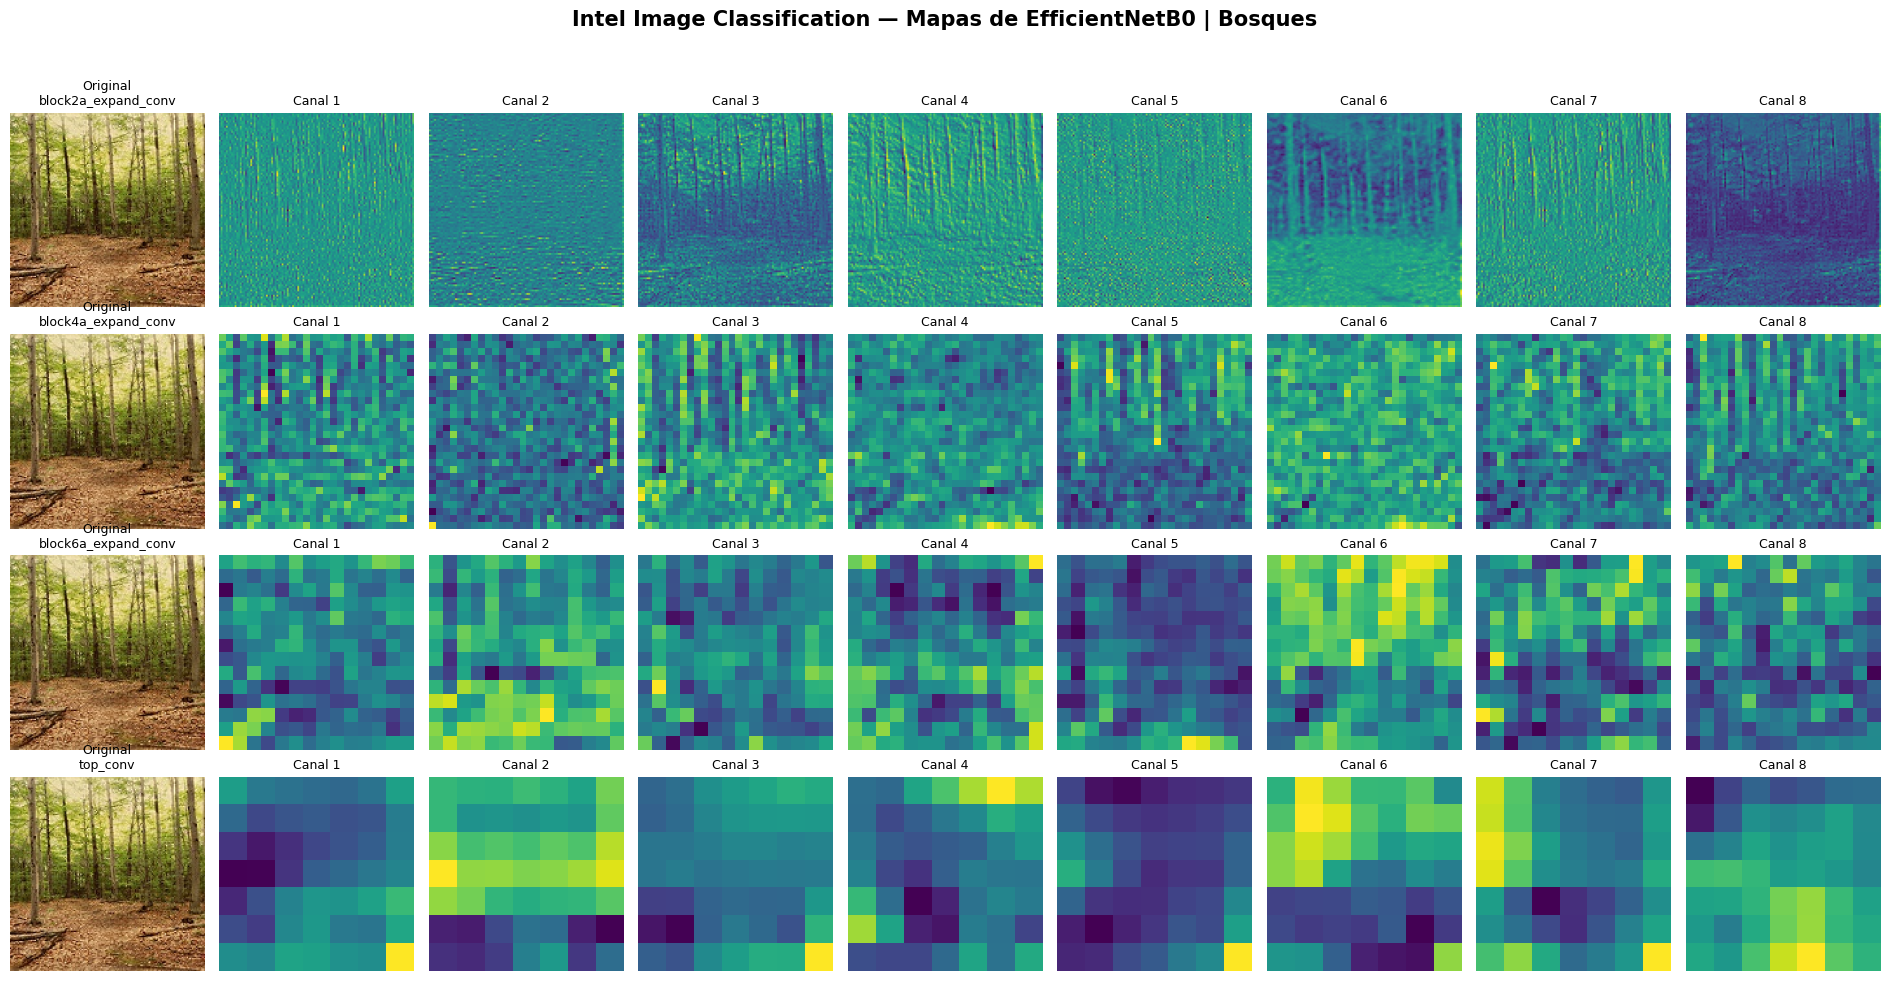

In [13]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Seleccionar cuatro capas de EfficientNetB0
capas = [
    "block2a_expand_conv",
    "block4a_expand_conv",
    "block6a_expand_conv",
    "top_conv",
]

# Extraer los mapas de las cuatro capas en una sola pasada
extractor_2 = tf.keras.Model(
    inputs=base_model_2.input,
    outputs=[base_model_2.get_layer(nombre).output for nombre in capas]
)

# Tomar una foto de validación y usar el preprocesamiento anterior
imagen_original, etiqueta = next(iter(val_raw_2))
nombre_clase = CLASS_NAMES_2[int(etiqueta.numpy())]
imagen_preparada, _ = preprocess_val_2(imagen_original, etiqueta)
lote = tf.expand_dims(imagen_preparada, axis=0)

mapas_por_capa = extractor_2(lote, training=False)

# Mostrar la foto original y los primeros ocho canales de cada capa
fig, axes = plt.subplots(len(capas), 9, figsize=(19, 10))

for fila, (nombre_capa, mapas) in enumerate(zip(capas, mapas_por_capa)):
    mapas = mapas[0].numpy()

    axes[fila, 0].imshow(imagen_original.numpy())
    axes[fila, 0].set_title(f"Original\n{nombre_capa}", fontsize=9)
    axes[fila, 0].axis("off")

    for canal in range(8):
        ax = axes[fila, canal + 1]
        ax.imshow(mapas[:, :, canal], cmap="viridis")
        ax.set_title(f"Canal {canal + 1}", fontsize=9)
        ax.axis("off")

fig.suptitle(
    f"Intel Image Classification — Mapas de EfficientNetB0 | {nombre_clase}",
    fontsize=15,
    fontweight="bold"
)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### 2.7. Comparación de características con t-SNE

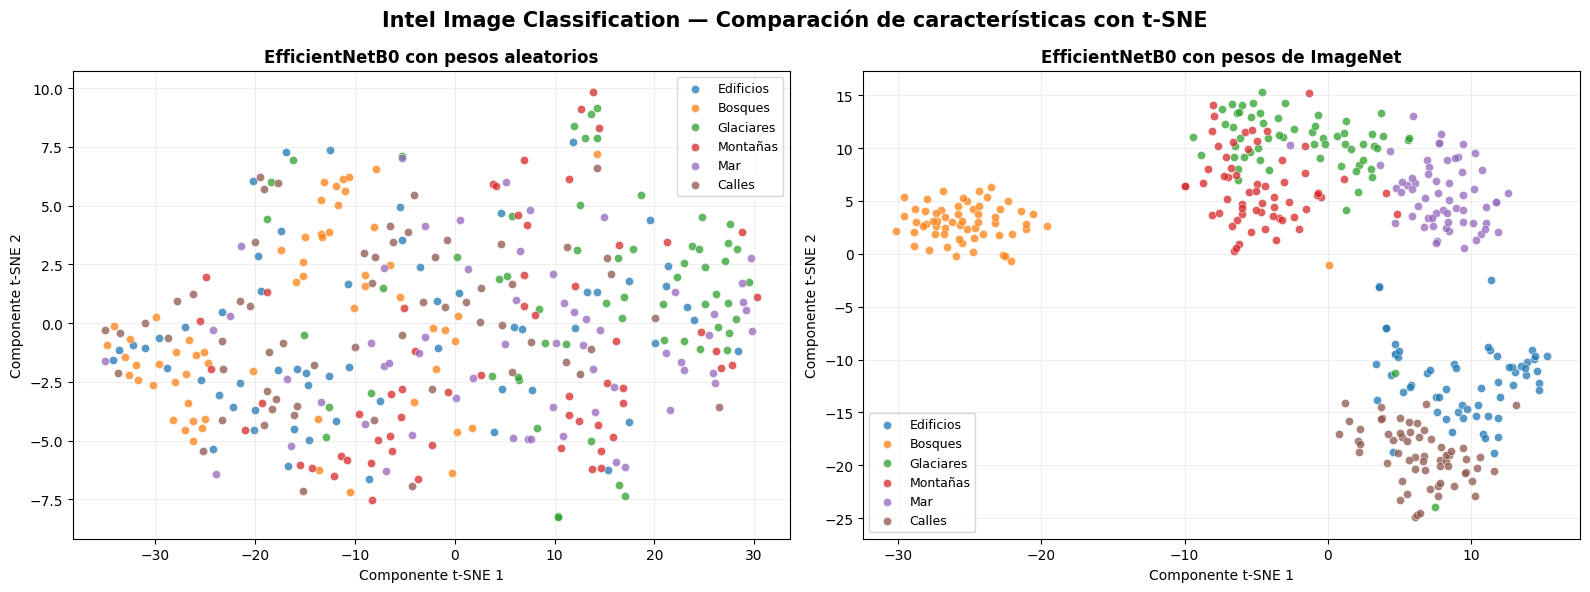

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.manifold import TSNE

# Elegir las mismas 60 fotos por clase para ambas redes
rng = np.random.default_rng(42)
etiquetas_val_array = np.asarray(etiquetas_val)

indices = np.concatenate([
    rng.choice(
        np.flatnonzero(etiquetas_val_array == clase),
        size=60,
        replace=False
    )
    for clase in range(NUM_CLASSES_2)
])
rng.shuffle(indices)

rutas_muestra = [rutas_val[i] for i in indices]
etiquetas_muestra = etiquetas_val_array[indices]

# Preparar las imágenes igual que en validación
muestra_ds = (
    crear_dataset_intel(rutas_muestra, etiquetas_muestra)
    .map(preprocess_val_2, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE_2)
    .prefetch(tf.data.AUTOTUNE)
)

# Crear una EfficientNetB0 con la misma arquitectura y pesos aleatorios
tf.keras.utils.set_random_seed(42)
base_aleatoria_2 = tf.keras.applications.EfficientNetB0(
    weights=None,
    include_top=False,
    input_shape=(*IMG_SIZE_2, 3)
)

# Convertir los mapas de salida de cada red en vectores de características
def extraer_caracteristicas(base, dataset):
    vectores = []
    for imagenes, _ in dataset:
        mapas = base(imagenes, training=False)
        vectores.append(tf.reduce_mean(mapas, axis=(1, 2)).numpy())
    return np.concatenate(vectores, axis=0)

caracteristicas_aleatorias = extraer_caracteristicas(base_aleatoria_2, muestra_ds)
caracteristicas_imagenet = extraer_caracteristicas(base_model_2, muestra_ds)

# Proyectar los vectores de cada red a dos dimensiones
def proyectar_tsne(caracteristicas):
    return TSNE(
        n_components=2,
        perplexity=30,
        init="pca",
        learning_rate="auto",
        random_state=42
    ).fit_transform(caracteristicas)

aleatorio_2d = proyectar_tsne(caracteristicas_aleatorias)
imagenet_2d = proyectar_tsne(caracteristicas_imagenet)

# Mostrar las seis clases con los mismos colores en ambos gráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colores = plt.get_cmap("tab10")

for ax, puntos, titulo in [
    (axes[0], aleatorio_2d, "EfficientNetB0 con pesos aleatorios"),
    (axes[1], imagenet_2d, "EfficientNetB0 con pesos de ImageNet"),
]:
    for clase, nombre in enumerate(CLASS_NAMES_2):
        mascara = etiquetas_muestra == clase
        ax.scatter(
            puntos[mascara, 0], puntos[mascara, 1],
            color=colores(clase), label=nombre,
            s=35, alpha=0.75, edgecolors="white", linewidths=0.4
        )

    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Componente t-SNE 1")
    ax.set_ylabel("Componente t-SNE 2")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)

fig.suptitle(
    "Intel Image Classification — Comparación de características con t-SNE",
    fontsize=15, fontweight="bold"
)
fig.tight_layout()
plt.show()

### ✅ Conclusión del Ejemplo 2 — Intel Image Classification

| Métrica | Valor |
|---|---|
| **Modelo base** | EfficientNetB0 preentrenado en ImageNet, con aproximadamente 4 millones de parámetros congelados |
| **Clases** | Edificios, bosques, glaciares, montañas, mar y calles |
| **Imágenes etiquetadas** | 17,034 en total: 11,227 de entrenamiento, 2,807 de validación y 3,000 de prueba |
| **Parámetros entrenables** | 167,302 del clasificador |
| **Mejor exactitud en validación** | 93,23 % |
| **Exactitud final en prueba** | 93,07 % |
| **Aumento de datos** | Volteo horizontal, rotación, zoom y ajuste de contraste |
| **Evaluación** | Matriz de confusión y reporte de clasificación |
| **Visualización** | Mapas de características por capa y comparación con t-SNE |

> EfficientNetB0 permitió reutilizar características aprendidas en ImageNet para clasificar seis tipos de escenas. Se mantuvo congelado el modelo base y se entrenó únicamente el clasificador. En las 3,000 imágenes de prueba, el modelo obtuvo **93,07 %**. La confusión más frecuente fue clasificar imágenes de **montañas** como **glaciares**, con **59** errores según la matriz de confusión.

*IS056B — Ingeniería del Conocimiento | UNCP 2026-II | Msc. Jaime Huaytalla Pariona*